# Autocomplete and Autocorrect Data Analytics
**Oasis Infobyte Internship · Data Analytics · Level 2 — Task 5**<br>
**Author:** Ojewumi Asaph Felix

**Objective:** build and evaluate the two text-prediction features of a keyboard — **autocomplete** (predict the next word) and **autocorrect** (fix a misspelled word) — on a real text corpus, compare two approaches for each, and measure their precision and recall.

**Corpus:** 6 classic novels from **Project Gutenberg** (public domain): *Pride and Prejudice*, *The Adventures of Sherlock Holmes*, *Moby Dick*, *Frankenstein*, *A Tale of Two Cities* and *Dracula* — about **830,000 words**.

> **Key results**
> - **Autocomplete:** a trigram model with bigram back-off puts the right next word in its **top 3 suggestions 24 % of the time** (bigram alone: 23 %).
> - **Autocorrect:** the **Damerau-Levenshtein** algorithm (which also handles swapped letters) clearly beats plain **Levenshtein**: precision **0.87 vs 0.73**, recall **0.81 vs 0.68** on 494 misspelled words, and **23 vs 17** of 25 common real-life typos fixed.
> - About **7 % of typos produce another valid word** ("from" → "form"): a dictionary-based corrector cannot detect them.

**Contents**
1. Building the corpus
2. NLP preprocessing
3. Word frequencies
4. Autocomplete: n-gram models
5. Testing autocomplete on 10 prefixes
6. Autocorrect: edit-distance models
7. Testing autocorrect on real misspellings
8. Precision and recall
9. Algorithm comparison and visualisations
10. Limitations vs. production keyboards

In [1]:
import re
import glob
import random
import time
from collections import Counter, defaultdict
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

pd.set_option("display.float_format", "{:,.3f}".format)
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#b9b8b3", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#cfcecb", "axes.labelcolor": MUTED, "axes.titleweight": "bold",
    "axes.titlesize": 12.5, "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.titlepad": 12,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#ecebe8", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

## 1. Building the Corpus
Each Gutenberg file starts and ends with a licence text. We keep only the book itself, between the `*** START OF …` and `*** END OF …` markers.

In [2]:
books = {}
for path in sorted(glob.glob("data/*.txt")):
    text = open(path, encoding="utf-8-sig").read()
    body = text.split("*** START OF")[1].split("***", 1)[1].split("*** END OF")[0]
    books[path.split("\\")[-1].split("/")[-1].replace(".txt", "")] = body

pd.DataFrame({"characters": {b: len(t) for b, t in books.items()},
              "words (approx.)": {b: len(t.split()) for b, t in books.items()}})

,characters,words (approx.)
a_tale_of_two_cities,757611,135886
dracula,845931,161321
frankenstein,419343,75042
moby_dick,1218983,212796
pride_and_prejudice,728751,127360
sherlock_holmes,562214,104506


## 2. NLP Preprocessing
1. **Sentence splitting** (on `.`, `!`, `?`) — predictions should not jump from one sentence to the next.
2. **Lowercasing**.
3. **Tokenisation and punctuation removal**: we keep only words made of letters (and inner apostrophes such as *don't*).
4. **Stopword removal — only for the frequency analysis.** Words like *the, of, and* carry no topic, so they are removed when we look for the *most meaningful* words. But they are **kept for autocomplete**: they are exactly the words people type most, and a keyboard must be able to predict them ("I would like **to**…").

Sentences are then split at random into a **training set (90 %)** used to build the models and a **test set (10 %)** used only for evaluation.

In [3]:
sentences = []
for body in books.values():
    for s in re.split(r"(?<=[.!?])\s+", body):
        words = re.findall(r"[a-z]+(?:'[a-z]+)?", s.lower())
        if len(words) >= 3:
            sentences.append(words)

random.seed(42)
random.shuffle(sentences)
cut = int(len(sentences) * 0.9)
train, test = sentences[:cut], sentences[cut:]

n_tokens = sum(map(len, sentences))
print(f"Sentences: {len(sentences):,}  ·  tokens: {n_tokens:,}")
print(f"Train: {len(train):,} sentences  ·  Test: {len(test):,} sentences")
print("Example:", " ".join(train[0][:20]))

Sentences: 35,024  ·  tokens: 827,433
Train: 31,521 sentences  ·  Test: 3,503 sentences
Example: darcy cried a young lucas who came with his sisters i should not care how proud i was


## 3. Word Frequencies

Vocabulary: 24,909 different words
Stopwords make up 60% of all words


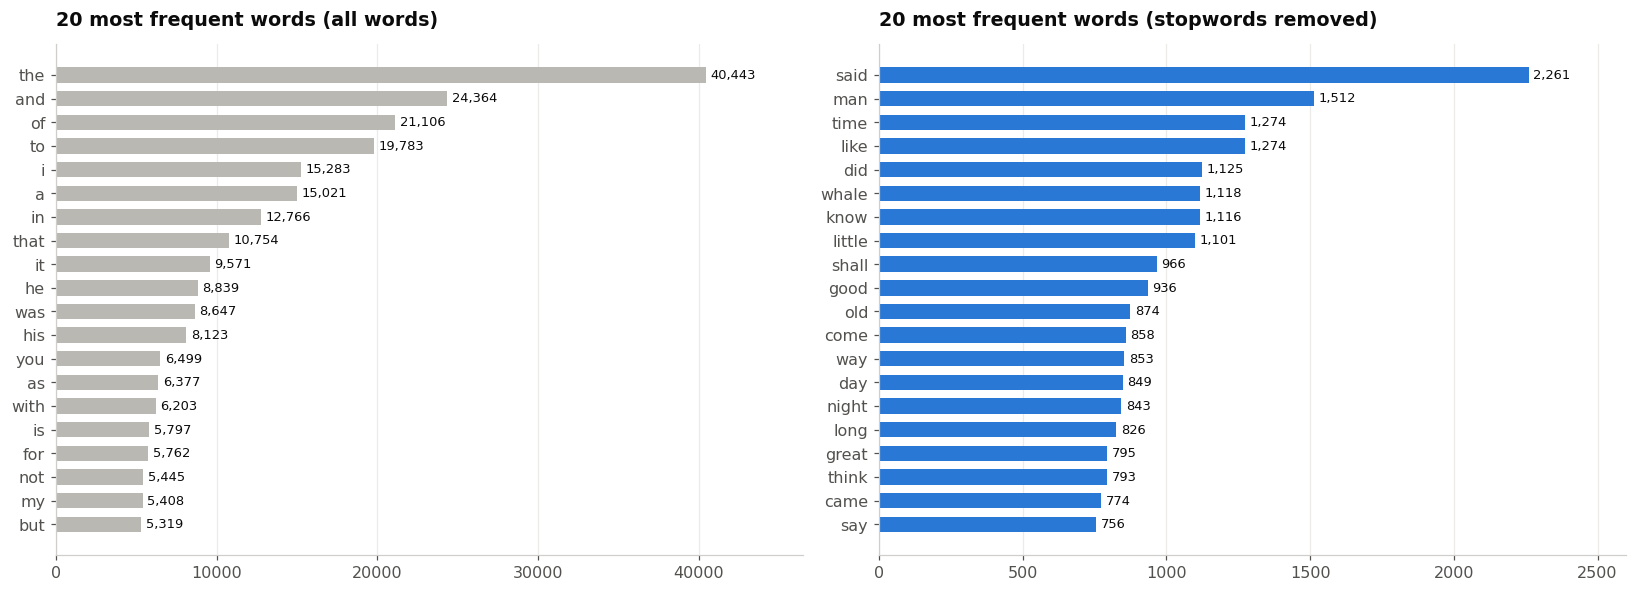

In [4]:
unigrams = Counter(w for s in train for w in s)
vocab = set(unigrams)
content = Counter({w: c for w, c in unigrams.items() if w not in ENGLISH_STOP_WORDS and len(w) > 2})
print(f"Vocabulary: {len(vocab):,} different words")
print(f"Stopwords make up {1 - sum(content.values()) / sum(unigrams.values()):.0%} of all words")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, counter, title, color in [(axes[0], unigrams, "20 most frequent words (all words)", GREY),
                                  (axes[1], content, "20 most frequent words (stopwords removed)", BLUE)]:
    top = pd.Series(dict(counter.most_common(20))).sort_values()
    b = ax.barh(top.index, top.values, color=color, height=0.65)
    ax.bar_label(b, labels=[f"{v:,}" for v in top.values], padding=3, color=INK, fontsize=8.5)
    ax.set_xlim(0, top.max() * 1.15)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("images/top_words.png")
plt.show()

**Observations:**
- A few function words dominate: *the, of, and, to, i, a* — stopwords make up more than half of all the words typed.
- Without stopwords, the most frequent words reflect narrative fiction: *said, man, time, like, know, little, old, night…* — and **whale** (6th), which shows that *Moby Dick* is the largest book of the corpus.
- The vocabulary (≈ 25,000 words) is the **dictionary** used by autocorrect.

## 4. Autocomplete: N-gram Models
An **n-gram model** predicts the next word from the previous **n − 1** words, using how often each continuation appeared in the training text.

- **Approach A — Bigram:** look only at the **last word**. After *"i am"* it looks at what usually follows *"am"*.
- **Approach B — Trigram with back-off:** look at the **last two words** (*"i am"*). If this pair was never seen, or gives fewer than 3 suggestions, **fall back** on the bigram to fill the list.

A sentence-start marker `<s>` lets the model also predict the first word of a sentence.

In [5]:
bigrams, trigrams = defaultdict(Counter), defaultdict(Counter)
for s in train:
    s = ["<s>"] + s
    for a, b in zip(s, s[1:]):
        bigrams[a][b] += 1
    for a, b, c in zip(s, s[1:], s[2:]):
        trigrams[(a, b)][c] += 1

def suggest_bigram(context, k=3):
    return [w for w, _ in bigrams[context[-1]].most_common(k)]

def suggest_trigram(context, k=3):
    out = [w for w, _ in trigrams[tuple(context[-2:])].most_common(k)] if len(context) >= 2 else []
    for w in suggest_bigram(context, k):                 # back-off to fill the list
        if len(out) >= k:
            break
        if w not in out:
            out.append(w)
    return out

print(f"{len(bigrams):,} bigram contexts · {len(trigrams):,} trigram contexts")

24,126 bigram contexts · 250,395 trigram contexts


## 5. Testing Autocomplete on 10 Prefixes

In [6]:
prefixes = ["i am", "it was", "in the", "do not", "i have", "she was", "the old",
            "as soon", "there is", "my dear"]
rows = []
for p in prefixes:
    ctx = p.split()
    rows.append({"prefix": p, "bigram top 3": ", ".join(suggest_bigram(ctx)),
                 "trigram top 3": ", ".join(suggest_trigram(ctx))})
pd.DataFrame(rows).set_index("prefix")

,bigram top 3,trigram top 3
prefix,,
i am,"not, sure, i","not, sure, afraid"
it was,"a, the, not","a, the, not"
in the,"same, whale, other","morning, world, same"
do not,"to, be, a","know, think, fear"
i have,"been, a, no","been, no, not"
she was,"a, the, not","in, not, a"
the old,"man, and, fashioned","man, bailey, chapel"
as soon,"as, after, be","as, have, after"
there is,"a, the, not","no, a, nothing"


**Observations:** the trigram model uses more context and gives more natural continuations. After *"do not"* it proposes **know, think, fear**, whereas the bigram only looks at *"not"* and proposes *to, be, a*; after *"there is"* the trigram suggests **no, a, nothing**, and after *"my dear"* forms of address typical of the novels (**madam, sir**). When the context is common in any position (*"it was"* → *a, the, not*), both models agree.

## 6. Autocorrect: Edit-Distance Models
The **edit distance** between two words is the minimum number of single-letter operations needed to turn one into the other.

- **Approach A — Levenshtein distance:** 3 operations — **insert**, **delete**, **substitute** a letter. Swapping two letters (*"teh"* → *"the"*) costs **2** operations.
- **Approach B — Damerau-Levenshtein distance:** the same, plus **transposition** of two adjacent letters, which costs **1**. This matches a very common typing error.

The corrector works like the classic algorithm of Peter Norvig:
1. If the word is in the dictionary, keep it.
2. Otherwise, generate every string at distance 1 and keep those that are real words; if there are none, try distance 2.
3. Among the candidates at the smallest distance, choose the **most frequent word** in the corpus.

In [7]:
LETTERS = "abcdefghijklmnopqrstuvwxyz"

def edits1(word, transpositions):
    splits = [(word[:i], word[i:]) for i in range(len(word) + 1)]
    deletes = {a + b[1:] for a, b in splits if b}
    substitutes = {a + c + b[1:] for a, b in splits if b for c in LETTERS}
    inserts = {a + c + b for a, b in splits for c in LETTERS}
    edits = deletes | substitutes | inserts
    if transpositions:
        edits |= {a + b[1] + b[0] + b[2:] for a, b in splits if len(b) > 1}
    return edits

def correct(word, transpositions):
    if word in vocab:
        return word
    candidates = [w for w in edits1(word, transpositions) if w in vocab]
    if not candidates:
        candidates = [w2 for w1 in edits1(word, transpositions) for w2 in edits1(w1, transpositions) if w2 in vocab]
    return max(candidates, key=unigrams.get) if candidates else word

correct_lev = lambda w: correct(w, transpositions=False)
correct_dam = lambda w: correct(w, transpositions=True)

# quick self-check of the two distances
assert correct_dam("teh") == "the" and correct_lev("teh") != "the"
print("'teh' →  Levenshtein:", correct_lev("teh"), " |  Damerau-Levenshtein:", correct_dam("teh"))

'teh' →  Levenshtein: ten  |  Damerau-Levenshtein: the


## 7. Testing Autocorrect on Real Misspellings
### 7.1 Twenty-five common real-life typos

In [8]:
common_typos = {"teh": "the", "recieve": "receive", "beleive": "believe", "freind": "friend", "untill": "until",
                "becuase": "because", "thier": "their", "whcih": "which", "wich": "which", "acheive": "achieve",
                "tommorow": "tomorrow", "occured": "occurred", "begining": "beginning", "seperate": "separate",
                "definately": "definitely", "goverment": "government", "neccessary": "necessary", "wierd": "weird",
                "adress": "address", "beautifull": "beautiful", "happend": "happened", "knowlege": "knowledge",
                "familar": "familiar", "realy": "really", "writting": "writing"}
assert all(v in vocab for v in common_typos.values())      # every expected word exists in the corpus

typo_table = pd.DataFrame([{"typo": t, "expected": e, "Levenshtein": correct_lev(t), "Damerau-Levenshtein": correct_dam(t)}
                           for t, e in common_typos.items()]).set_index("typo")
for col in ["Levenshtein", "Damerau-Levenshtein"]:
    print(f"{col:<20}: {(typo_table[col] == typo_table['expected']).sum()} / {len(typo_table)} corrected")
typo_table

Levenshtein         : 17 / 25 corrected
Damerau-Levenshtein : 23 / 25 corrected


,expected,Levenshtein,Damerau-Levenshtein
typo,,,
teh,the,ten,the
recieve,receive,relieve,receive
beleive,believe,belrive,believe
freind,friend,friend,friend
untill,until,until,until
becuase,because,because,because
thier,their,thief,their
whcih,which,which,which
wich,which,with,with


**Observations:** Damerau-Levenshtein fixes **23 of the 25** typos, Levenshtein **17**. The difference comes from **swapped letters** (*teh, thier, beleive, recieve, acheive, wierd*): for Levenshtein a swap costs 2 edits, so a more frequent word at distance 1 wins (*teh* → *ten*, *thier* → *thief*). Both fail on *"wich"* (→ *with*, a more frequent word one letter away than *which*) and *"adress"* (→ *dress*, reached by deleting one letter instead of adding one): **frequency alone cannot always pick the intended word**.

### 7.2 A larger, automatic test set
To measure precision and recall reliably, we also take **1,000 random words from the test sentences**: 500 are **misspelled** with one random typing error (letter deleted, inserted, replaced or two letters swapped), and 500 are kept **correct** to check that the corrector does not damage good words.

In [9]:
def make_typo(word, rng):
    i = rng.randrange(len(word))
    op = rng.choice(["delete", "insert", "substitute", "transpose"])
    if op == "delete":
        return word[:i] + word[i + 1:]
    if op == "insert":
        return word[:i] + rng.choice(LETTERS) + word[i:]
    if op == "substitute":
        return word[:i] + rng.choice(LETTERS.replace(word[i], "")) + word[i + 1:]
    i = min(i, len(word) - 2)
    return word[:i] + word[i + 1] + word[i] + word[i + 2:]

rng = random.Random(1)
pool = [w for s in test for w in s if len(w) >= 4 and w in vocab]
sample = rng.sample(pool, 1000)
misspelled = [(make_typo(w, rng), w) for w in sample[:500]]
misspelled = [(m, w) for m, w in misspelled if m != w]          # a swap of two equal letters changes nothing
correct_words = [(w, w) for w in sample[500:]]
real_word_errors = sum(m in vocab for m, _ in misspelled)
print(f"Misspelled words: {len(misspelled)}  ·  correct words: {len(correct_words)}")
print(f"Typos that produce another valid word: {real_word_errors} ({real_word_errors / len(misspelled):.0%}), e.g.",
      [(m, w) for m, w in misspelled if m in vocab][:4])

Misspelled words: 494  ·  correct words: 500
Typos that produce another valid word: 35 (7%), e.g. [('hall', 'shall'), ('bore', 'borne'), ('ave', 'have'), ('wer', 'were')]


## 8. Precision and Recall
**Autocomplete** (top-3 suggestions, evaluated on every word of the test sentences):
- **Precision** = among the times the model **made suggestions**, how often was the real next word in its top 3?
- **Recall** = among **all words** to predict, how often was the real next word in the top 3? (A model that stays silent on unknown contexts loses recall.)
- We also report **top-1 accuracy**: the first suggestion is exactly right.

**Autocorrect:**
- **Precision** = among the words the corrector **changed**, how many were changed to the **right** word?
- **Recall** = among all **misspelled** words, how many were **fixed**?
- **False alarms** = correct words wrongly changed.

In [10]:
def evaluate_autocomplete(suggest):
    total = made = hits = top1 = 0
    for s in test:
        s = ["<s>"] + s
        for i in range(1, len(s)):
            suggestions = suggest(s[:i])
            total += 1
            made += bool(suggestions)
            hits += s[i] in suggestions
            top1 += bool(suggestions) and suggestions[0] == s[i]
    return {"precision (top 3)": hits / made, "recall (top 3)": hits / total, "top-1 accuracy": top1 / total}

start = time.time()
ac_results = pd.DataFrame({"Bigram": evaluate_autocomplete(suggest_bigram),
                           "Trigram + back-off": evaluate_autocomplete(suggest_trigram)}).T
print(f"Evaluated on {sum(len(s) for s in test):,} test words in {time.time() - start:.0f} s")
ac_results

Evaluated on 82,082 test words in 31 s


,precision (top 3),recall (top 3),top-1 accuracy
Bigram,0.232,0.229,0.126
Trigram + back-off,0.245,0.242,0.137


In [11]:
def evaluate_autocorrect(corrector):
    changed = fixed = 0
    outcome = {"misspelled → right": 0, "misspelled → wrong": 0, "correct → right": 0, "correct → wrong": 0}
    for typo, truth in misspelled:
        out = corrector(typo)
        changed += out != typo
        fixed += out == truth
        outcome["misspelled → right" if out == truth else "misspelled → wrong"] += 1
    false_alarms = 0
    for word, _ in correct_words:
        out = corrector(word)
        false_alarms += out != word
        outcome["correct → right" if out == word else "correct → wrong"] += 1
    changed += false_alarms
    metrics = {"precision": fixed / changed, "recall": fixed / len(misspelled),
               "false alarms": false_alarms, "accuracy (all 1,000 words)": (fixed + len(correct_words) - false_alarms) / (len(misspelled) + len(correct_words))}
    return metrics, outcome

lev_metrics, lev_outcome = evaluate_autocorrect(correct_lev)
dam_metrics, dam_outcome = evaluate_autocorrect(correct_dam)
acc_results = pd.DataFrame({"Levenshtein": lev_metrics, "Damerau-Levenshtein": dam_metrics}).T
acc_results

,precision,recall,false alarms,"accuracy (all 1,000 words)"
Levenshtein,0.730,0.678,0.000,0.840
Damerau-Levenshtein,0.871,0.810,0.000,0.905


## 9. Algorithm Comparison and Visualisations

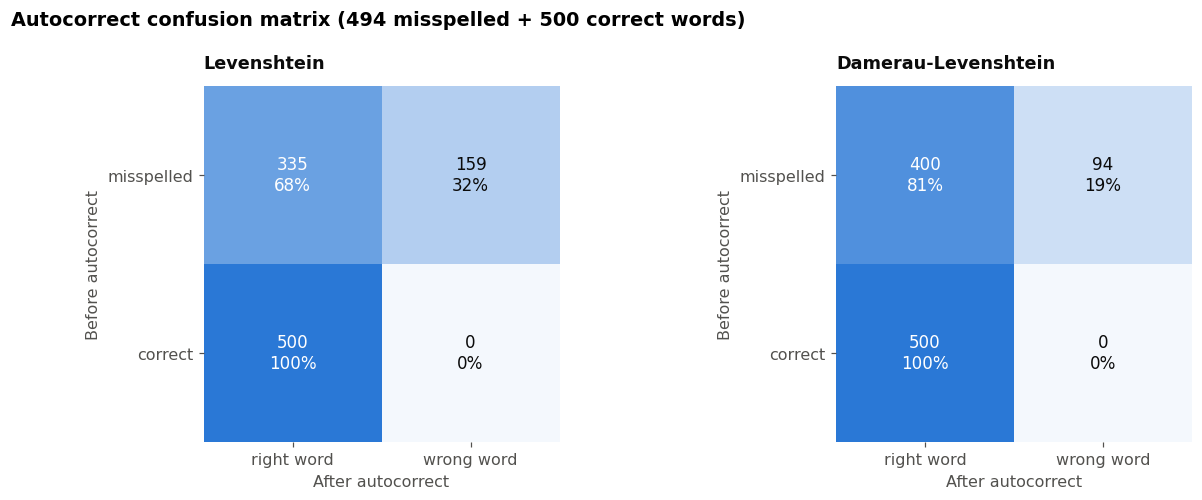

In [12]:
cmap = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", BLUE])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (name, outcome) in zip(axes, [("Levenshtein", lev_outcome), ("Damerau-Levenshtein", dam_outcome)]):
    cm = np.array([[outcome["misspelled → right"], outcome["misspelled → wrong"]],
                   [outcome["correct → right"], outcome["correct → wrong"]]])
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap=cmap, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            share = cm[i, j] / cm[i].sum()
            ax.text(j, i, f"{cm[i, j]}\n{share:.0%}", ha="center", va="center", color="white" if share > 0.55 else INK, fontsize=11)
    ax.set_xticks([0, 1], ["right word", "wrong word"]); ax.set_yticks([0, 1], ["misspelled", "correct"])
    ax.set_xlabel("After autocorrect"); ax.set_ylabel("Before autocorrect")
    ax.set_title(name, fontsize=11.5)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
plt.suptitle("Autocorrect confusion matrix (494 misspelled + 500 correct words)", fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.savefig("images/autocorrect_confusion.png")
plt.show()

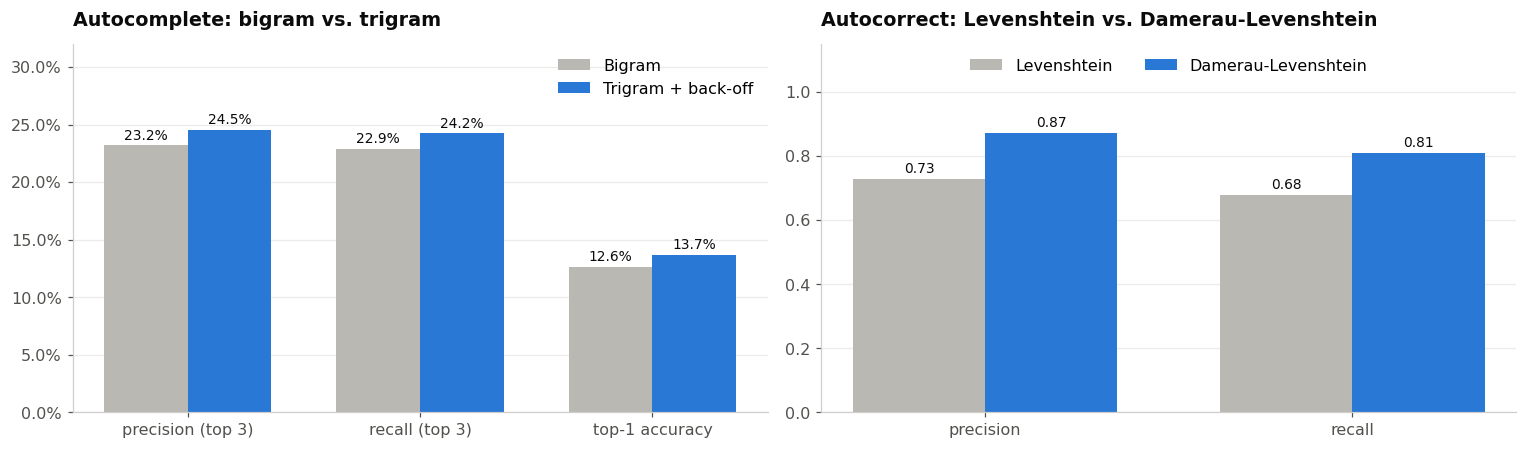

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(3)
for i, (name, color) in enumerate([("Bigram", GREY), ("Trigram + back-off", BLUE)]):
    vals = ac_results.loc[name].values
    b = axes[0].bar(x + (i - 0.5) * 0.36, vals, width=0.36, color=color, label=name)
    axes[0].bar_label(b, labels=[f"{v:.1%}" for v in vals], padding=2, fontsize=9, color=INK)
axes[0].set_xticks(x, ac_results.columns)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].set_ylim(0, 0.32)
axes[0].set_title("Autocomplete: bigram vs. trigram")
axes[0].legend(frameon=False)
axes[0].grid(axis="x", visible=False)

x = np.arange(2)
for i, (name, color) in enumerate([("Levenshtein", GREY), ("Damerau-Levenshtein", BLUE)]):
    vals = acc_results.loc[name, ["precision", "recall"]].astype(float).values
    b = axes[1].bar(x + (i - 0.5) * 0.36, vals, width=0.36, color=color, label=name)
    axes[1].bar_label(b, labels=[f"{v:.2f}" for v in vals], padding=2, fontsize=9, color=INK)
axes[1].set_xticks(x, ["precision", "recall"])
axes[1].set_ylim(0, 1.15)
axes[1].set_title("Autocorrect: Levenshtein vs. Damerau-Levenshtein")
axes[1].legend(frameon=False, loc="upper center", ncol=2)
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig("images/algorithm_comparison.png")
plt.show()

**Observations:**
- **Autocomplete:** the trigram model with back-off is slightly better on every metric (top-3 recall ≈ 24 % vs. 23 %). The gain is small because most word pairs of the test set are **rare**: with only 830,000 words of training text, many trigrams were never seen, so the model often falls back on the bigram. Predicting the exact next word is hard: even a 1-in-4 hit rate in the top 3 is useful on a phone keyboard.
- **Autocorrect:** **Damerau-Levenshtein is clearly better** (precision 0.87 vs. 0.73, recall 0.81 vs. 0.68), because a quarter of the typos are **swapped letters**, which it handles in one step.
- **No false alarms** on the 500 correct words: they are all in the dictionary, so the corrector leaves them alone.
- The remaining errors are mostly **real-word errors** (a typo that is itself a valid word, ≈ 7 % of typos, which no dictionary-based corrector can see) and **ambiguous typos** where a more frequent word is at the same distance.

## 10. Limitations vs. Production Systems such as Google Keyboard (Gboard)
| Our implementation | Production keyboards |
|---|---|
| Trained on **6 novels from the 19th century** (≈ 830k words) | Trained on **billions of words** of modern text, and adapted to each user's own vocabulary |
| **N-gram** model: sees only the last 1–2 words | **Neural language models** (LSTM, Transformers) that use the whole sentence and the conversation |
| Spelling based only on **edit distance + word frequency** | Uses the **keyboard layout** (*"q"* next to *"w"*), the **touch position** of the finger and gesture typing |
| Cannot detect **real-word errors** (*form* / *from*) | Uses context to fix them (*"I come form Paris"* → *from*) |
| Unknown names (*Abidjan*) would be "corrected" to a known word | Learns new words from the user and from contacts |
| No personalisation, English only | Personalised, multilingual, works offline on the phone with small optimised models |

**Conclusion:** simple, transparent methods already give a useful baseline — **Damerau-Levenshtein reaches 0.87 precision** for autocorrect, and the **trigram model** puts the right next word in its top 3 about one time in four. The biggest improvements would come from **much more (and more modern) training data**, **context-aware neural models**, and **keyboard-specific information** such as key distances.